# 06 — Posterior by unbiased Bayesian synthetic likelihood (uBSL)

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

Every previous rung gave an estimate, and located what limits its uncertainty:
- **[notebook 03](03_point_fit.ipynb):** the point fit works, but maximising the synthetic likelihood is hard.
- **[notebook 04](04_identifiability.ipynb):** local (Fisher) standard errors, trusted only to about a factor 2.
- **[notebook 05](05_bootstrap.ipynb):** the bootstrap and the response surface both flagged. The likelihood is
  **rough at the scale of the uncertainty**, so any method that *maximises* it inherits ~1 se of jitter. It is
  also **~2× too sharp** in one direction, because Σ̂ is estimated from only 40 runs.

**This rung changes strategy: instead of maximising, sample.** A Bayesian posterior averages over the
likelihood. We use the **unbiased Bayesian synthetic likelihood** of Price, Drovandi, Lee & Nott
(2018). It addresses both notebook 05 problems at once:
1. its likelihood estimator is exactly unbiased for the Gaussian density, removing the finite-n sharpening;
2. inside **pseudo-marginal MCMC**, fresh random numbers at every step turn the roughness into noise the
   chain averages out.

The protocol, including how n was chosen, was written down before running. The first run (2000
iterations per chain) passed R̂ but fell short on ESS. As the protocol's own remedy, the same chains were
**extended to 4000 iterations**. This notebook shows the extended run.

**Roadmap:**

| § | question | tool |
|---|---|---|
| Definitions | uBSL, pseudo-marginal MCMC, diagnostics | |
| 1 | how was n chosen? | pilot (pre-registered rule) |
| 2 | did the chains mix and agree? | traces, acceptance, R̂, ESS |
| 3 | what is the posterior? | marginals, pairs, intervals |
| 4 | how wide, compared with notebook 04 and notebook 05? | sd ratios |
| 5 | what this taught us | |

## Definitions

### The idea in one paragraph

Bayes' rule gives the posterior $p(\theta\mid\mathbf s_{\rm obs}) \propto p(\mathbf s_{\rm obs}\mid\theta)\,p(\theta)$.
We cannot evaluate the likelihood, but we can *estimate* it by simulation. A classic result (pseudo-marginal
MCMC; Andrieu & Roberts 2009) says that if the estimate is **unbiased** and positive, a Metropolis–Hastings
chain that uses it in place of the true likelihood still samples the *exact* posterior of the synthetic
likelihood, that is, the posterior given that the summaries are Gaussian (not the posterior of the true
likelihood of the tracks, which no method here reaches). The noise only makes the chain slower. The plain synthetic likelihood of notebook 03 is *not* unbiased, since $\mathcal N(\mathbf s;\hat\mu,\hat\Sigma)$
is biased for finite $n$. uBSL replaces it with an estimator that is.

### uBSL (Ghurye & Olkin 1969; used by Price et al. 2018; formula as in An et al. 2019, eq. 3)

At θ, simulate $n$ runs, with summaries $\mathbf s_1..\mathbf s_n \in\mathbb R^d$ ($d = 7$). Let $\mu_n$ be their mean
and $M_n = (n-1)\Sigma_n = \sum_i(\mathbf s_i-\mu_n)(\mathbf s_i-\mu_n)^\top$. Then

$$\hat p(\mathbf s_{\rm obs}\mid\theta) = (2\pi)^{-d/2}\,\frac{c(d,n-2)}{c(d,n-1)\,(1-1/n)^{d/2}}\;|M_n|^{-\frac{n-d-2}{2}}\;
\Psi\!\Big(M_n - \frac{(\mathbf s_{\rm obs}-\mu_n)(\mathbf s_{\rm obs}-\mu_n)^\top}{1-1/n}\Big)^{\frac{n-d-3}{2}}$$

$$c(k,v) = \frac{2^{-kv/2}\,\pi^{-k(k-1)/4}}{\prod_{i=1}^k \Gamma\!\big(\tfrac{v-i+1}{2}\big)}, \qquad
\Psi(A) = \begin{cases}|A| & A \text{ positive definite}\\ 0 & \text{otherwise}\end{cases}$$

- It is **exactly unbiased** for the Gaussian density $\mathcal N(\mathbf s_{\rm obs};\mu(\theta),\Sigma(\theta))$ when the summaries
  are Gaussian and $n > d+3$.
- `tests/test_observe.py` checks this: the mean of 40 000 estimates matches the exact density to 3%.
- It can be exactly **0**, when Ψ = 0. That happens when $\mathbf s_{\rm obs}$ is far from the simulated cloud, and more often for small n.
- No covariance shrinkage: shrinkage would break the unbiasedness.

### The sampler (`flockladder.ubsl.chain`)

Random-walk Metropolis–Hastings in $x = \log\theta$:
- **Proposal:** $x' = x + L\mathbf z$, $\mathbf z\sim\mathcal N(0,I)$, where $LL^\top = C$ is notebook 04's Fisher covariance. Steps are
  about one local se, correctly correlated.
- **Prior:** uniform in $\log\theta$ on notebook 03's box. Proposals outside the box are rejected.
- **Accept** with probability $\min\big(1, \hat p(\mathbf s_{\rm obs}\mid\theta')/\hat p(\mathbf s_{\rm obs}\mid\theta)\big)$.
  - $\hat p(\theta')$ uses **fresh** random numbers.
  - $\hat p(\theta)$ of the current point is **kept, never re-estimated**. That is what makes the method exact.
  - The price: if the current estimate happens to be high, the chain can **stick** for a while.

### Diagnostics
- **Split-R̂:** each chain is cut in half, and the variance *between* half-chains is compared with the variance
  *within* them. 1 means all agree; the criterion is < 1.05.
- **ESS** (effective sample size): how many independent draws the correlated chain is worth. The criterion is
  ≥ 400 in total per parameter. It sets the precision of posterior summaries: a sd is known to about
  $1/\sqrt{2\,\mathrm{ESS}}$ relative.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from flockladder.results import load
from flockladder.synlik import TRUTH
from flockladder.ubsl import ess, split_rhat

NAMES = ("η", "r", "v₀")
THETA_HAT = np.array([2.0035, 1.0141, 0.03001])  # notebook 03
C = load("a5_bootstrap")["fisher_cov"]
SE = np.sqrt(np.diag(C))  # notebook 04's Fisher covariance

# The six chains took ~12.5 h on 6 processes. They are loaded from results/; scripts/a6_posterior.py
# regenerates them (every likelihood evaluation goes through a disk cache, so an interrupted run resumes).
P = load("a6_posterior")
out = [{"x": x, "ll": ll, "acc": acc} for x, ll, acc in zip(P["x"], P["ll"], P["acc"], strict=True)]
BURN = 500
X = np.array([o["x"][BURN + 1 :] for o in out])  # (6 chains, 1500, 3), log θ
print(f"{len(out)} chains × {out[0]['x'].shape[0] - 1} iterations; {BURN} discarded as burn-in")

6 chains × 4000 iterations; 500 discarded as burn-in


## 1. How n was chosen (pre-registered pilot)

The number of simulations per likelihood estimate, n, trades cost against noise. Price et al. recommend a
standard deviation of the log-likelihood estimator of about 1.5–2. **The rule, written before looking:** at θ̂,
10 fresh seeds for each n ∈ {20, 30, 40}; take the smallest n with sd(log p̂) ≤ 2.

| n | sd(log p̂) over 10 seeds | finite estimates |
|---|---|---|
| 20 | undefined (one estimate was 0) | 9 of 10 |
| **30** | **1.39** | 10 of 10 |
| 40 | 2.84 | 10 of 10 |

**How to read this.**
- **n = 20 is rejected:** one of its ten estimates was exactly 0 (Ψ = 0), so its log is −∞ and the sd is undefined.
  A chain would treat such points as impossible.
- **n = 30 is chosen:** sd 1.39, within the recommended range.
- **n = 40 gave a *larger* sd (2.84) than n = 30.** That cannot be the true trend (more simulations should mean less
  noise). With only 10 seeds a sd is itself uncertain by ~25%, and one outlier can dominate. It is noted, not
  interpreted, and the rule was applied as written.

## 2. Did the chains mix and agree?

Six chains start about 1 se apart around θ̂ and run 4000 iterations each.
- The first 2000 are the original run, and the check at the top confirms the extension replayed them
  exactly.
- The trace plots show $\log\theta$ against iteration for every chain. The grey band is the discarded burn-in
  (500).

acceptance per chain: [0.149 0.148 0.156 0.136 0.154 0.154]
longest run of rejections per chain: [np.int64(61), np.int64(105), np.int64(66), np.int64(91), np.int64(105), np.int64(97)]

     split-R̂    ESS   criteria: R̂ < 1.05, ESS ≥ 400
η       1.010    674   ok / ok
r       1.004    792   ok / ok
v₀      1.011    676   ok / ok

per-chain posterior means of log θ (rows = chains):
[[ 0.6981  0.0075 -3.5054]
 [ 0.6991  0.0092 -3.505 ]
 [ 0.6997  0.0092 -3.5048]
 [ 0.7006  0.0099 -3.5044]
 [ 0.701   0.0088 -3.5044]
 [ 0.7008  0.0095 -3.5044]]


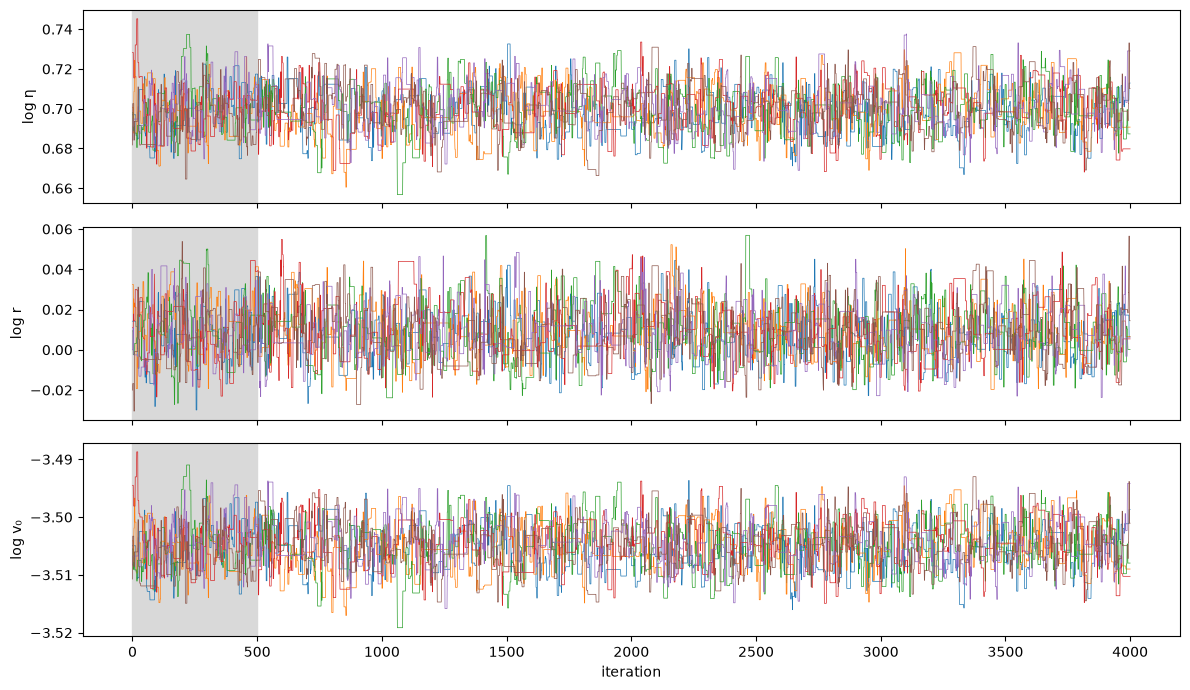

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for q, ax in enumerate(axes):
    for o in out:
        ax.plot(o["x"][:, q], lw=0.5)
    ax.axvspan(0, BURN, color="0.85", zorder=0)
    ax.set_ylabel(f"log {NAMES[q]}")
axes[-1].set_xlabel("iteration")
plt.tight_layout()

acc = [o["acc"].mean() for o in out]
print("acceptance per chain:", np.round(acc, 3))
runs = []
for o in out:
    a = o["acc"]
    r = np.diff(np.flatnonzero(np.r_[True, a, True])) - 1
    runs.append(r.max())
print("longest run of rejections per chain:", runs)
print(f"\n{'':4s} {'split-R̂':>8s} {'ESS':>6s}   criteria: R̂ < 1.05, ESS ≥ 400")
for q in range(3):
    rh, es = split_rhat(X[:, :, q]), ess(X[:, :, q])
    print(
        f"{NAMES[q]:4s} {rh:8.3f} {es:6.0f}   {'ok' if rh < 1.05 else 'FAIL'} / {'ok' if es >= 400 else 'SHORT'}"
    )
print("\nper-chain posterior means of log θ (rows = chains):")
print(X.mean(1).round(4))

**How to read this.**
- **Traces:** each coloured line is a chain.
  - They look like **staircases**: flat stretches where the chain stays put, then jumps. That is the
    pseudo-marginal signature. After accepting a point whose likelihood was *over*-estimated by luck, the
    chain rejects everything for a while.
  - The longest such stretches are 61–105 iterations, short compared with 4000.
- **No trends, and all six chains overlap** throughout. They began only ~1 se from θ̂, so the burn-in was
  hardly needed.
- **Acceptance 14–16%** in every chain: low, as expected with noisy likelihood estimates, and very
  consistent across chains.
- **R̂ = 1.010, 1.004, 1.011** (criterion < 1.05). The per-chain means differ by at most 0.003 in log (0.3%).
- **ESS = 674, 792, 676** (criterion ≥ 400). **Both pre-registered criteria are met: the chains have converged.**
- **History:** at 2000 iterations R̂ already passed (≤ 1.035) but the ESS was 221–286. Doubling the length
  roughly tripled the ESS, because the first stretch (partly burn-in) weighed less in the longer run.

## 3. The posterior

Pooling the 6 × 1500 post-burn-in draws:
- **marginal histograms** of each parameter. The dashed line is notebook 04's Fisher normal (centred on the posterior
  mean, sd = notebook 04's se), for comparison of widths;
- **pair plots** of the draws;
- a table of means and 80% and 95% equal-tailed intervals, and whether θ* is inside.

         mean           80% interval           95% interval  θ* in 95%
η      2.0136   [1.9830, 2.0442]   [1.9651, 2.0611]   yes
r      1.0091   [0.9921, 1.0274]   [0.9851, 1.0375]   yes
v₀     0.0301   [0.0299, 0.0302]   [0.0298, 0.0303]   yes

correlations (log): η–r +0.58  η–v₀ +0.98  r–v₀ +0.56   (Fisher, 04: +0.76, +0.99, +0.74)


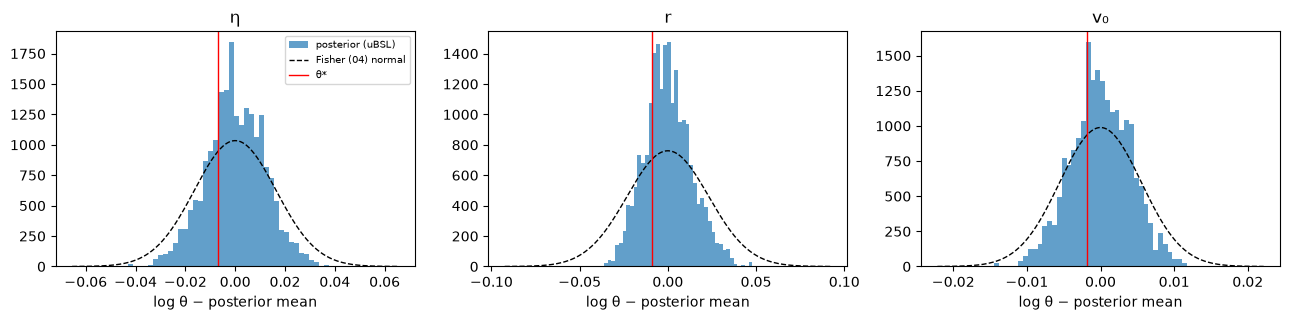

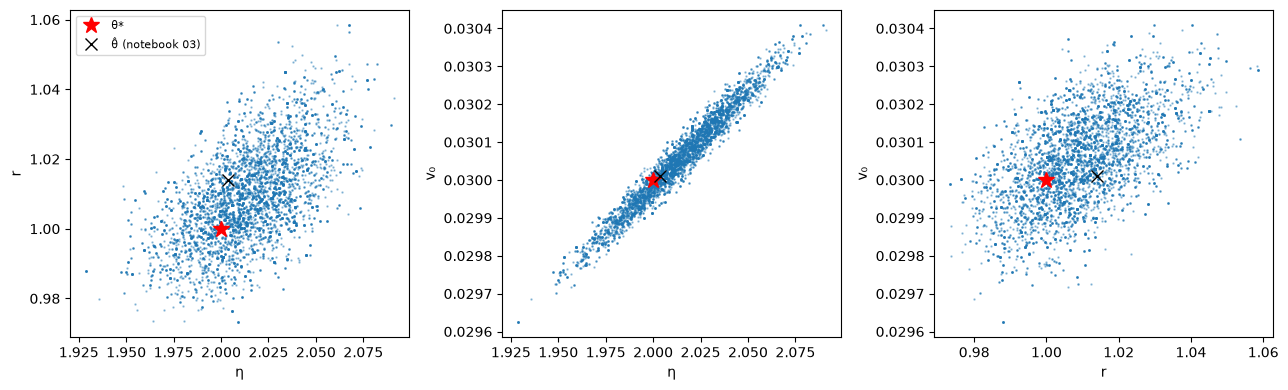

In [3]:
flat = X.reshape(-1, 3)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for q, ax in enumerate(axes):
    dev = flat[:, q] - flat[:, q].mean()
    counts, edges, _ = ax.hist(dev, bins=40, alpha=0.7, label="posterior (uBSL)")
    xs = np.linspace(-4 * SE[q], 4 * SE[q], 200)
    w = edges[1] - edges[0]
    ax.plot(
        xs,
        len(dev) * w * np.exp(-0.5 * (xs / SE[q]) ** 2) / (SE[q] * np.sqrt(2 * np.pi)),
        "k--",
        lw=1,
        label="Fisher (04) normal",
    )
    ax.axvline(np.log(TRUTH[q]) - flat[:, q].mean(), c="r", lw=1, label="θ*")
    ax.set(title=NAMES[q], xlabel="log θ − posterior mean")
axes[0].legend(fontsize=7)
plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (i, j) in zip(axes, ((0, 1), (0, 2), (1, 2))):
    ax.plot(np.exp(flat[::3, i]), np.exp(flat[::3, j]), ".", ms=1.5, alpha=0.4)
    ax.plot(TRUTH[i], TRUTH[j], "r*", ms=12, label="θ*")
    ax.plot(THETA_HAT[i], THETA_HAT[j], "kx", ms=9, label="θ̂ (notebook 03)")
    ax.set(xlabel=NAMES[i], ylabel=NAMES[j])
axes[0].legend(fontsize=8)
plt.tight_layout()

print(f"{'':4s} {'mean':>8s} {'80% interval':>22s} {'95% interval':>22s}  θ* in 95%")
for q in range(3):
    c = np.exp(flat[:, q])
    lo8, hi8 = np.quantile(c, [0.1, 0.9])
    lo9, hi9 = np.quantile(c, [0.025, 0.975])
    print(
        f"{NAMES[q]:4s} {c.mean():8.4f}   [{lo8:.4f}, {hi8:.4f}]   [{lo9:.4f}, {hi9:.4f}]   {'yes' if lo9 <= TRUTH[q] <= hi9 else 'NO'}"
    )
R = np.corrcoef(flat, rowvar=False)
print(
    f"\ncorrelations (log): η–r {R[0, 1]:+.2f}  η–v₀ {R[0, 2]:+.2f}  r–v₀ {R[1, 2]:+.2f}   (Fisher, 04: +0.76, +0.99, +0.74)"
)

**How to read this.**
- **Marginals (top):**
  - Each posterior (blue) is **narrower than notebook 04's Fisher normal** (dashed): clearly for r, less for η and v₀.
  - The true value (red line) lies inside every posterior, near its centre.
  - The histograms are a little lumpy because the chains stick (§2): repeated values pile up in single bins.
- **Pairs (bottom):**
  - **η–v₀ is a thin straight line** (correlation +0.98). The data pin down one *combination* of noise and
    speed very tightly. More noise shortens the net displacement, and a larger v₀ compensates: the notebook 03 "speed
    valley", seen as posterior samples. It *is* identified, along a thin, nearly straight ridge.
  - **η–r and r–v₀** are moderate positive tilts (+0.58, +0.56), weaker than notebook 04's local +0.76 and +0.74.
  - θ* (red star) and notebook 03's point estimate (×) both sit inside the cloud in all three panels.
- **Intervals (table):**
  - 95% intervals: η [1.965, 2.061] (±2.4%), r [0.985, 1.038] (±2.6%), v₀ [0.0298, 0.0303] (±0.8%).
  - **θ* is inside all three.** One check, not a coverage study.
  - The posterior means (2.014, 1.009, 0.0301) are within 1% of the truth.

## 4. How wide is the posterior, compared with notebook 04 and notebook 05?

The posterior sd of $\log\theta$ against notebook 04's local Fisher se, and against notebook 05's two flagged estimates.

In [4]:
sd = flat.std(0, ddof=1)
print(
    f"{'':4s} {'posterior sd':>13s} {'04 se':>8s} {'post./04 se':>13s} {'05 (max.)':>10s} {'05 2nd (rob.)':>13s}"
)
for q, (first, second) in enumerate(((0.91, 0.81), (0.72, 0.91), (0.87, 0.80))):
    print(
        f"{NAMES[q]:4s} {sd[q]:13.4f} {SE[q]:8.4f} {sd[q] / SE[q]:13.2f} {first:10.2f} {second:13.2f}"
    )
print(
    f"\nprecision of the posterior sd itself (ESS ≈ 670–790): about ±{100 / np.sqrt(2 * 700):.0f}%"
)

      posterior sd    04 se   post./04 se  05 (max.) 05 2nd (rob.)
η           0.0118   0.0164          0.72       0.91          0.81
r           0.0133   0.0231          0.58       0.72          0.91
v₀          0.0040   0.0055          0.73       0.87          0.80

precision of the posterior sd itself (ESS ≈ 670–790): about ±3%


**How to read this.**
- **The posterior is narrower than every previous estimate:** 0.72, 0.58 and 0.73 of notebook 04's se, against notebook 05's
  0.91 / 0.72 / 0.87 and the second attempt's robust 0.81 / 0.91 / 0.80.
- **The notebook 05 numbers were expected to be too wide:** they included ~1 se of optimiser jitter per refit. The
  posterior has no optimiser.
- **Why is notebook 04's Fisher se wider? We checked two explanations afterwards**, separately (not shown in these notebooks):
  - Notebook 04's ±10% finite differences slightly underestimated the slopes. With ±3% the se shrinks 8–15%.
  - Notebook 04 left out the information carried by how the *covariance* of the summaries changes with θ. That adds
    7–9% for r, ~0 for the others.
  - Together they explain about half the gap. The posterior is still 0.82 / 0.73 / 0.84 of the corrected se.
    The rest is open; a candidate is that the observed run is atypical (~2 sd off in every summary, notebook 03), so
    the curvature *at this data* differs from the average (Fisher) curvature.
- **Precision of these ratios:** with ESS ≈ 700 the posterior sds are good to about ±3%, so the gaps are real.

## 5. What this taught us

**Sampling instead of maximising: the run converged.** Six chains agree (R̂ ≤ 1.011, ESS 674–792),
the posterior contains the truth, and nothing was tuned after looking. The only change (the extension) was
the remedy the protocol names. This choice addressed both problems of notebook 05:
- the likelihood's roughness is averaged by the chain, not chased by an optimiser;
- the finite-n bias of Σ̂ is removed by the unbiased estimator. No correction had to be guessed.

**The posterior of θ from one run of 40 particles (5000 steps observed every 10):**

| | mean | 95% interval | width (±) |
|---|---|---|---|
| η | 2.014 | [1.965, 2.061] | ±2.4% |
| r | 1.009 | [0.985, 1.038] | ±2.6% |
| v₀ | 0.0301 | [0.0298, 0.0303] | ±0.8% |

θ* = (2, 1, 0.03) is inside all three.

**What the posterior adds that point fits could not show:**
- **The shape of the uncertainty:** η and v₀ lie on a thin straight ridge (corr +0.98). They are known *as a
  pair* much better than individually.
- **The size:** 0.58–0.73 of notebook 04's local Fisher se. Notebook 04's local estimate is conservative (about half of that is
  now explained). Notebook 05's bootstrap was inflated by optimiser jitter. The posterior is the first width measured
  without either problem.

**The series in one line:** a rate (02: a well-defined time of ordering, strongly dependent on v₀) → a point fit
(03: on target, and the geometry of the valley) → identifiability (04: r determined; the η–r ridge only for φ-type
summaries) → error bars (05: their size, and the roughness of ℓ at the scale of the uncertainty) →
**a posterior (06: clean, converged).**

**Stopping criterion.** If a posterior summary of θ is what is needed, **stop here.**

**Cost.** 6 chains × 4000 iterations × 30 simulations = 24 012 likelihood evaluations, 12.5 h on 6 processes.
Here they are loaded from `results/`.